<a href="https://colab.research.google.com/github/shahedtheboss/digit-recognizer-CNN-kaggle/blob/main/digit_recognizer_kaggle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset,DataLoader
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import kagglehub

In [ ]:
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [ ]:
torch.manual_seed(42)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.competition_download("digit-recognizer")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/competitions/digit-recognizer


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os
# List files in the downloaded directory to see the exact structure
files = os.listdir(path)
print("Files in dataset directory:", files)

# Dynamically construct the correct train CSV path
train_csv = [f for f in files if 'train' in f.lower()][0]
train_path = os.path.join(path, train_csv)

df = pd.read_csv(train_path)
print("Loaded shape:", df.shape)
df.head()

Files in dataset directory: ['test.csv', 'sample_submission.csv', 'train.csv']
Loaded shape: (42000, 785)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
df.shape

(42000, 785)

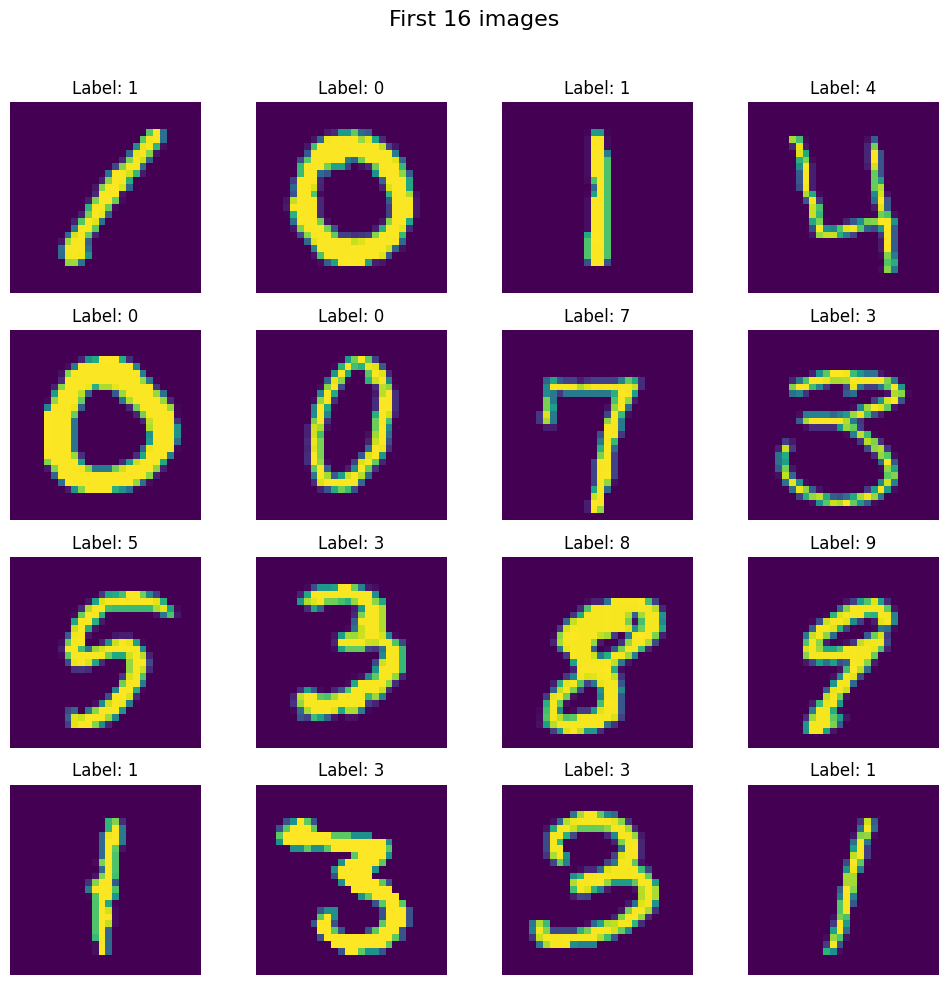

In [ ]:
fig, axes = plt.subplots(4,4, figsize=(10,10))
fig.suptitle("First 16 images", fontsize=16)

for i, ax in enumerate(axes.flat):
    img = df.iloc[i, 1:].values.reshape(28, 28)  # Reshape to 28x28
    ax.imshow(img)  # Display in grayscale
    ax.axis('off')  # Remove axis for a cleaner look
    ax.set_title(f"Label: {df.iloc[i, 0]}")  # Show the label

plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust layout to fit the title
plt.show()

In [ ]:
X = df.iloc[:, 1:].values
y= df.iloc[:, 0].values

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X_train = X_train/255.0
X_test = X_test/255.0

In [ ]:
from torchvision import transforms

class CustomDataset(Dataset):
  def __init__(self, features, labels, transform=None):


    self.features = torch.tensor(features, dtype=torch.float32).reshape(-1, 1,28,28)
    self.labels = torch.tensor(labels, dtype=torch.long)
    self.transform = transform

  def __len__(self):
    return len(self.features)


  def __getitem__(self, idx):
    image = self.features[idx]
    label = self.labels[idx]

    if self.transform is not None:
      image = self.transform(image)

    return image, label




In [ ]:
train_transform = transforms.RandomAffine(
    degrees=7,
    translate=(0.08, 0.08),
    fill=0
)
train_dataset = CustomDataset(X_train, y_train, transform=train_transform)
test_dataset = CustomDataset(X_test, y_test)

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True,pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, pin_memory=True)

In [ ]:
from torch.nn.modules.dropout import Dropout
class MyNN(nn.Module):
  def __init__(self, input_features):
    super().__init__()

    self.features = nn.Sequential(
        nn.Conv2d(input_features, 32, kernel_size=3, padding='same' ),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),
        nn.Conv2d(32, 64, kernel_size=3, padding='same' ),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(64*7*7, 128),
        nn.ReLU(),
        nn.Dropout(p=0.4),

        nn.Linear(128,64),
        nn.ReLU(),
        nn.Dropout(p=0.4),
        nn.Linear(64,10)
    )


  def forward(self, x):
    x=self.features(x)
    x = self.classifier(x)


    return x

In [ ]:
learning_rate = 0.001
epochs = 100

In [ ]:
model = MyNN(1)

model.to(device)

critetion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(),lr=learning_rate, weight_decay=0.0001)


In [ ]:
# @title
for epoch in range(epochs):

  total_epoch_loss = 0

  for batch_features, batch_labels in train_loader:

    batch_features = batch_features.to(device)
    batch_labels = batch_labels.to(device)

    outputs = model(batch_features)
    loss = critetion(outputs, batch_labels)


    optimizer.zero_grad()
    loss.backward()

    optimizer.step()

    total_epoch_loss = total_epoch_loss + loss.item()

  avg_loss = total_epoch_loss/len(train_loader)
  print(f"Epoch: {epoch} Loss: {avg_loss}")


Epoch: 0 Loss: 0.6054122158317339
Epoch: 1 Loss: 0.25074740995253836
Epoch: 2 Loss: 0.20776402468482652
Epoch: 3 Loss: 0.17288684180804662
Epoch: 4 Loss: 0.1594906863818566
Epoch: 5 Loss: 0.1436409275836888
Epoch: 6 Loss: 0.1396625405585482
Epoch: 7 Loss: 0.12862468883040407
Epoch: 8 Loss: 0.11921377630815619
Epoch: 9 Loss: 0.11492715708734025
Epoch: 10 Loss: 0.11279333547467277
Epoch: 11 Loss: 0.10541167726651543
Epoch: 12 Loss: 0.10023537790491467
Epoch: 13 Loss: 0.09984379343378047
Epoch: 14 Loss: 0.09204088470322036
Epoch: 15 Loss: 0.09445143999177076
Epoch: 16 Loss: 0.08855852644668803
Epoch: 17 Loss: 0.08468596440872976
Epoch: 18 Loss: 0.07947001276803868
Epoch: 19 Loss: 0.0780434869400536
Epoch: 20 Loss: 0.08223673305695965
Epoch: 21 Loss: 0.07757834630530505
Epoch: 22 Loss: 0.0747515877393917
Epoch: 23 Loss: 0.07550401240188097
Epoch: 24 Loss: 0.06987406039366588
Epoch: 25 Loss: 0.0647222912778324
Epoch: 26 Loss: 0.07037475025591751
Epoch: 27 Loss: 0.06813680498594685
Epoch: 28

In [ ]:
model.eval()

MyNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.4, inplace=False)
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [ ]:
# evaluation on test data
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in test_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

0.9935714285714285


In [ ]:
sample = pd.read_csv(os.path.join(path, 'sample_submission.csv'))
sample.head()

,ImageId,Label
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0


In [ ]:
# @title
sample = pd.read_csv(os.path.join(path, "sample_submission.csv"))

model.eval()
predictions = []

with torch.no_grad():
    for batch_features in test_loader:

        # Extract the image tensor from the list
        if isinstance(batch_features, (list, tuple)):
            batch_features = batch_features[0]

        batch_features = batch_features.to(device)

        outputs = model(batch_features)
        predicted = outputs.argmax(dim=1)

        predictions.extend(predicted.cpu().numpy())

assert len(predictions) == len(sample), (
    f"Expected {len(sample)} predictions, got {len(predictions)}"
)

sample["Label"] = predictions
sample.to_csv("submission.csv", index=False)

print(sample.head())
print("Submission shape:", sample.shape)

AssertionError: Expected 28000 predictions, got 8400

In [ ]:

# Load Kaggle's actual test.csv (28,000 images)
kaggle_test_df = pd.read_csv(os.path.join(path, "test.csv"))

# Normalize pixels exactly as in training
X_kaggle = kaggle_test_df.values.astype(np.float32) / 255.0

# Create dataset and loader using your existing CustomDataset
dummy_labels = np.zeros(len(X_kaggle), dtype=np.int64)

kaggle_test_dataset = CustomDataset(X_kaggle, dummy_labels)

kaggle_test_loader = DataLoader(
    kaggle_test_dataset,
    batch_size=64,
    shuffle=False,
    pin_memory=True
)

# Generate predictions for Kaggle's test images
model.eval()
predictions = []

with torch.no_grad():
    for batch_features, _ in kaggle_test_loader:
        batch_features = batch_features.to(device)

        outputs = model(batch_features)
        predicted = outputs.argmax(dim=1)

        predictions.extend(predicted.cpu().numpy())

# Fill the official submission template
sample = pd.read_csv(os.path.join(path, "sample_submission.csv"))

assert len(predictions) == len(sample) == 28000

sample["Label"] = predictions
sample.to_csv("submission-2-augmented_digit.csv", index=False)

print(sample.head())
print("Submission shape:", sample.shape)
print("Missing values:", sample.isna().sum().sum())
print("Saved submission.csv successfully!")


   ImageId  Label
0        1      2
1        2      0
2        3      9
3        4      0
4        5      3
Submission shape: (28000, 2)
Missing values: 0
Saved submission.csv successfully!


In [ ]:

# evaluation on training data
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in train_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

1.0
